# Seeing Pando at 10 m with Sentinel-2 and STAC (Python)

**Question.** What does the forest around the Pando aspen stand look like at Sentinel-2's 10 m resolution, in true color and in vegetation greenness?

By the end of this lesson you will have a pair of maps like these, made from one clear Sentinel-2 scene, and files you can open in any GIS:

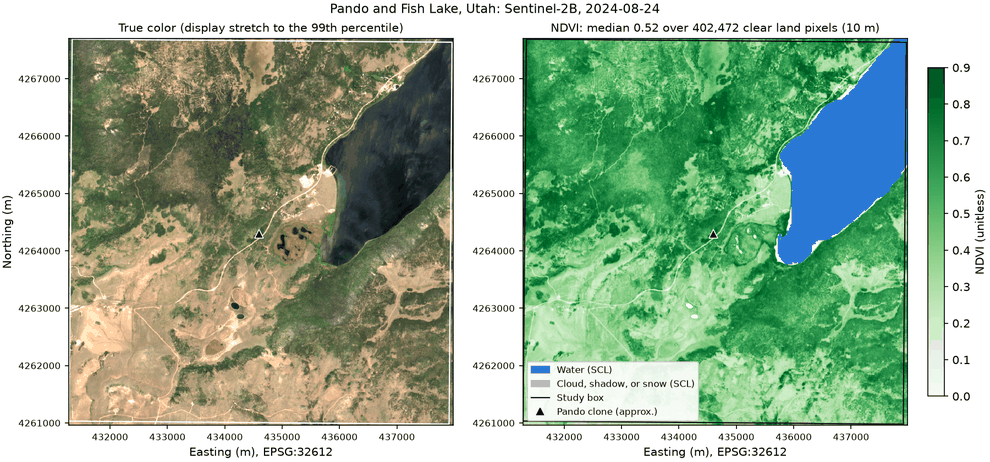

**You will learn to**

1. search a **STAC** catalog and explain its collections, items, and assets;
2. read a small window of imagery from public cloud storage, applying the scale and offset recorded in the catalog;
3. mask clouds with Sentinel-2's scene classification, then make a true-color image and an NDVI map at 10 m.

## Before starting

- **Setup.** Run the [getting-started notebook](../getting-started/) first. This lesson needs the Trees from Space Python environment, but **no account**: the imagery is public.
- **CHPC.** Run the getting-started notebook in the same kind of OnDemand session first. If it reports that the session can reach the internet, run this lesson as it is. If not, fetch the data with a short transfer job, after which the whole notebook runs offline from the cache ([CHPC guide](../../docs/getting-started/chpc.md)).
- **Data volume.** A few megabytes, read directly from cloud storage and saved to the lesson cache.
- **Time.** About 20 minutes of reading and running. The first run spends a minute or two reading data; reruns take seconds.
- **Related lesson.** [Mapping vegetation greenness with HLS](../hls-vegetation-map/) maps the same area at 30 m. This lesson can be done on its own.
- **Tested environments.** See the [lesson README](README.md).

## The data in brief

**Sentinel-2** is a pair of European Space Agency (ESA) satellites (Sentinel-2A, 2B, and since 2025 2C) carrying the MultiSpectral Instrument. Together they image most land every five days or less, in 13 spectral bands. Four bands have 10 m pixels: blue (B02), green (B03), red (B04), and near-infrared (B08). That is three times finer than the 30 m of Landsat and HLS, so each 30 m pixel holds nine Sentinel-2 pixels.

**Level-2A** products give **surface reflectance**: the fraction of sunlight the ground reflects in each band, from 0 to 1, after correcting for the atmosphere. They also include a **Scene Classification Layer (SCL)** at 20 m that labels each pixel as vegetation, water, cloud, cloud shadow, snow, and so on.

**Limits to keep in mind.** The scene classification is automatic and makes mistakes, especially with thin cloud and with shadows in steep terrain. NDVI from Sentinel-2's broad near-infrared band (B08) is close to, but not the same as, NDVI from HLS, which uses a narrower band and further adjustments. Finer pixels show more detail, but they do not make NDVI a measure of biomass: it still saturates over dense canopy.

### STAC in brief

A **STAC** catalog (SpatioTemporal Asset Catalog) describes geospatial data in a standard way, so the same code can search many providers:

| STAC term | Meaning | In this lesson |
| --- | --- | --- |
| Catalog | A searchable service | Earth Search, run by Element 84 on Amazon Web Services |
| Collection | One dataset | `sentinel-2-c1-l2a`: Sentinel-2 Level-2A, Collection 1 |
| Item | One scene: footprint, date, and properties such as cloud cover | One Sentinel-2 tile on one date |
| Asset | One file belonging to an item | Each band, the SCL, thumbnails, metadata |

Items and assets carry standard **extensions**: extra fields with agreed names. This lesson uses `eo:cloud_cover` (scene cloud cover), `raster:bands` (scale, offset, and no-data value), and `storage:requester_pays` (whether the reader pays for downloads).

## Settings

Everything you might change is in the next cell. Coordinates are longitude and latitude in decimal degrees (WGS84), in the order **west, south, east, north**. Dates use the format `"YYYY-MM-DD"`. If you run this notebook as a batch job, the job uses the values saved in this cell.

In [ ]:
# Study area: a box of longitude/latitude in degrees, ordered (west, south, east, north).
SITE_ID = "pando"
SITE_NAME = "Pando and Fish Lake, Utah"
BBOX = (-111.788, 38.495, -111.712, 38.555)

# Search window. Mid-July to mid-September avoids snow at this mountain site.
START_DATE = "2024-07-15"
END_DATE = "2024-09-15"

# The catalog and collection to search.
STAC_URL = "https://earth-search.aws.element84.com/v1"
COLLECTION = "sentinel-2-c1-l2a"

# Ask the catalog only for scenes with less cloud than this (percent of the whole scene).
MAX_CLOUD_COVER = 20

# Request limit: the most items to consider.
MAX_ITEMS = 20

# Scene classes that make a pixel unusable: 0 no data, 1 saturated or defective,
# 3 cloud shadow, 8 cloud (medium probability), 9 cloud (high probability),
# 10 thin cirrus, 11 snow or ice. (Class 6, water, is shown on the map instead.)
MASK_CLASSES = [0, 1, 3, 8, 9, 10, 11]

# The chosen scene must have at least this fraction of clear pixels in the study area.
MIN_CLEAR_FRACTION = 0.8

## Setup

The next cell loads the packages this lesson uses and sets up the folders for cached data and results. **pystac-client** searches STAC catalogs; **rasterio** reads the image files. In Google Colab it first installs two packages, which takes a minute.

In [ ]:
import json
import os
import socket
import subprocess
import sys
import time
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    colab_packages = ["pystac-client==0.9.1", "rasterio==1.5.0"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *colab_packages], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pystac
import pystac_client
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from rasterio.io import MemoryFile
from rasterio.shutil import copy as copy_raster
from rasterio.warp import transform as transform_points
from rasterio.warp import transform_bounds
from rasterio.windows import Window

RUN_STARTED = time.monotonic()


def find_repo_root(start: Path) -> Path | None:
    """Walk up from `start` to the folder holding the .tfs-root marker file."""
    for folder in [start, *start.parents]:
        if (folder / ".tfs-root").exists():
            return folder
    return None


REPO_ROOT = find_repo_root(Path.cwd())
BASE_DIR = Path("/content/trees-from-space") if IN_COLAB else (REPO_ROOT or Path.cwd())
CACHE_DIR = Path(os.environ.get("TFS_CACHE_DIR", BASE_DIR / "cache"))
OUTPUT_DIR = Path(os.environ.get("TFS_OUTPUT_DIR", BASE_DIR / "outputs"))

# One cache folder per study box, named by its coordinates.
box_name = "_".join(f"{value:.4f}" for value in BBOX)
SITE_CACHE = CACHE_DIR / "sentinel2" / f"{SITE_ID}_{box_name}"
LESSON_OUTPUT = OUTPUT_DIR / "sentinel2-stac" / "python"
SITE_CACHE.mkdir(parents=True, exist_ok=True)
LESSON_OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"Cache:   {SITE_CACHE}")
print(f"Results: {LESSON_OUTPUT}")

### Helpers for reading data once

As in the HLS lesson, every piece of downloaded data goes into the cache and is reused on later runs, so the notebook also works on a machine without internet access once the cache is filled. Each file is written under a temporary name and renamed only when complete.

The GDAL settings tell the library that reads the files not to list folders in cloud storage (which is slow), to read only `.tif` files, and to retry a few times before giving up. No credentials are needed.

In [ ]:
GDAL_OPTIONS = {
    "GDAL_DISABLE_READDIR_ON_OPEN": "EMPTY_DIR",
    "CPL_VSIL_CURL_ALLOWED_EXTENSIONS": ".tif",
    "GDAL_HTTP_MAX_RETRY": "4",
    "GDAL_HTTP_RETRY_DELAY": "2",
    "GDAL_HTTP_CONNECTTIMEOUT": "10",
    "GDAL_HTTP_TIMEOUT": "60",
}
STAC_HOST = STAC_URL.split("/")[2]


def network_available(host: str = STAC_HOST, timeout_s: float = 5) -> bool:
    """Return True if this machine can open a connection to the catalog."""
    if os.environ.get("TFS_OFFLINE") == "1":  # lets you test the offline route
        return False
    try:
        with socket.create_connection((host, 443), timeout=timeout_s):
            return True
    except OSError:
        return False


def offline_message(missing: Path) -> str:
    return (
        f"This machine cannot reach the internet, and the cache does not yet hold {missing.name}. "
        "Run the notebook once on a machine with internet access (on CHPC, use a transfer "
        "job; see docs/getting-started/chpc.md), then rerun it here."
    )


def write_atomically(path: Path, write) -> None:
    """Call write(temporary_path), then rename the result to `path`."""
    temporary = path.with_name(path.name + ".part")
    write(temporary)
    os.replace(temporary, path)


ONLINE = network_available()
print("Network: online" if ONLINE else "Network: offline (only cached data can be used)")

## 1. Search the catalog

`pystac_client.Client.open` connects to the catalog, and `search` asks it for items in one collection that overlap our box during our dates. The `query` argument asks the catalog itself to drop scenes with more cloud than `MAX_CLOUD_COVER`, so they are never sent to us. The search returns an **item collection**, which the next cell saves to the cache.

In [ ]:
def load_or_search() -> pystac.ItemCollection:
    """Return the search results, from the cache when possible."""
    path = SITE_CACHE / (
        f"search_{COLLECTION}_{START_DATE}_{END_DATE}_cloud{MAX_CLOUD_COVER}_max{MAX_ITEMS}.json"
    )
    if path.exists():
        print(f"{path.name} (cached)")
        return pystac.ItemCollection.from_file(str(path))
    if not ONLINE:
        raise RuntimeError(offline_message(path))
    catalog = pystac_client.Client.open(STAC_URL)
    print(f"Catalog: {catalog.title}")
    search = catalog.search(
        collections=[COLLECTION],
        bbox=BBOX,
        datetime=f"{START_DATE}T00:00:00Z/{END_DATE}T23:59:59Z",
        query={"eo:cloud_cover": {"lt": MAX_CLOUD_COVER}},
        max_items=MAX_ITEMS,
    )
    found = search.item_collection()
    write_atomically(path, lambda tmp: tmp.write_text(json.dumps(found.to_dict())))
    print(f"{len(found)} items found (searched the catalog)")
    return found


items = list(load_or_search())
if not items:
    raise RuntimeError(
        "No scenes matched. Check that BBOX is ordered (west, south, east, north), that "
        "START_DATE comes before END_DATE and falls within the Sentinel-2 record (from "
        "June 2015), or raise MAX_CLOUD_COVER."
    )

scenes = pd.DataFrame(
    {
        "item_id": item.id,
        "date": item.datetime.date(),
        "platform": item.properties.get("platform"),
        "tile": item.properties.get("grid:code"),
        "scene_cloud_pct": round(item.properties["eo:cloud_cover"], 2),
        "processing_baseline": item.properties.get("s2:processing_baseline"),
    }
    for item in items
).sort_values("date", ignore_index=True)
scenes

Each row is one **item**: one Sentinel-2 tile (`grid:code`) on one date. The item ID encodes the satellite, tile, and acquisition time, for example `S2A_T12SVH_20240829T182309_L2A`. The cloud cover is for the whole 110 km tile, as in the HLS lesson.

## 2. Look inside one item

An item's **assets** are its files. The next cell lists them for the first item, with each asset's resolution (`gsd`, ground sample distance, in meters) and where it is stored.

In [ ]:
example = items[0]
pd.DataFrame(
    {
        "asset": key,
        "title": asset.title,
        "gsd_m": asset.extra_fields.get("gsd"),
        "roles": ", ".join(asset.roles or []),
        "file": asset.href.split("/")[-1],
    }
    for key, asset in example.assets.items()
)

The four 10 m bands this lesson needs are `blue`, `green`, `red`, and `nir`. The scene classification is `scl`, at 20 m. The `visual` asset is a ready-made true-color image with 8-bit values for quick viewing, not for analysis.

**Can anyone read these files?** Before using a provider, check whether its files need a login, whether the links expire, and who pays for downloads. The `storage` fields of the item answer the last question, and the asset links themselves answer the first two:

In [ ]:
red_asset = example.assets["red"]
print("Requester pays:", example.properties.get("storage:requester_pays"))
print("Stored in:     ", example.properties.get("storage:platform"), example.properties.get("storage:region"))
print("Red band link: ", red_asset.href)
print("raster:bands:  ", red_asset.extra_fields["raster:bands"])

The link is a plain `https://` address in a public Amazon Web Services bucket: anyone can read it without a login, it does not expire, and the reader pays nothing. Other providers differ. Microsoft's Planetary Computer, for example, requires a short-lived signature added to each link before reading.

The `raster:bands` field gives the **scale** and **offset** that turn stored values into reflectance, and the **no-data** value:

reflectance = stored value × 0.0001 − 0.1

The offset of −0.1 exists because, since January 2022 (processing baseline 04.00), ESA stores reflectance with 1,000 added, so that dark pixels just below zero are not cut off. Collection 1 is ESA's reprocessing of the whole archive to this convention. **Watch out:** Earth Search's older collection, `sentinel-2-l2a`, lists the same offset in its catalog although many of its files already have it removed. Applying the offset there gives impossible negative reflectance. Always check a few values against what you expect.

## 3. Check the study area in each scene

The **Scene Classification Layer** gives each 20 m pixel one class number. Unlike the HLS Fmask layer, where each bit is a separate flag, these are plain categories:

| Class | Meaning | Used here |
| --- | --- | --- |
| 0 | No data | Masked |
| 1 | Saturated or defective | Masked |
| 2 | Dark area (often topographic shadow) | Kept |
| 3 | Cloud shadow | Masked |
| 4 | Vegetation | Kept |
| 5 | Not vegetated | Kept |
| 6 | Water | Shown on the map |
| 7 | Unclassified | Kept |
| 8, 9 | Cloud, medium and high probability | Masked |
| 10 | Thin cirrus | Masked |
| 11 | Snow or ice | Masked |

The next cell reads the study-area window of each scene's SCL and computes its clear fraction. The window covers the box's footprint in the tile's UTM projection, rounded outward to the **20 m grid**. Sentinel-2's 10 m and 20 m grids share their corner, so a window on the 20 m grid also falls exactly on whole 10 m pixels, and every band covers the same ground.

In [ ]:
SCL_WATER = 6
GRID_STEP_M = 20  # the coarsest grid used (SCL); the 10 m grid nests inside it


def aoi_window(src) -> Window:
    """Pixel window covering BBOX, rounded outward to the 20 m grid shared by all bands."""
    left, bottom, right, top = transform_bounds("EPSG:4326", src.crs, *BBOX, densify_pts=21)
    x0, y0, size = src.transform.c, src.transform.f, src.transform.a
    left = x0 + np.floor((left - x0) / GRID_STEP_M) * GRID_STEP_M
    right = x0 + np.ceil((right - x0) / GRID_STEP_M) * GRID_STEP_M
    top = y0 - np.floor((y0 - top) / GRID_STEP_M) * GRID_STEP_M
    bottom = y0 - np.ceil((y0 - bottom) / GRID_STEP_M) * GRID_STEP_M
    col0, row0 = round((left - x0) / size), round((y0 - top) / size)
    return Window(col0, row0, round((right - left) / size), round((top - bottom) / size))


def read_aoi_window(item: pystac.Item, asset_key: str) -> tuple[np.ndarray, dict, str]:
    """Return (pixels, metadata, status) for the study-area window of one asset."""
    path = SITE_CACHE / f"{item.id}.{asset_key}.aoi.tif"
    if not path.exists():
        if not ONLINE:
            raise RuntimeError(offline_message(path))
        with rasterio.Env(**GDAL_OPTIONS), rasterio.open(item.assets[asset_key].href) as src:
            window = aoi_window(src)
            pixels = src.read(1, window=window)
            profile = {
                "driver": "GTiff", "dtype": src.dtypes[0], "count": 1, "crs": src.crs,
                "width": window.width, "height": window.height, "nodata": src.nodata,
                "transform": src.window_transform(window), "compress": "deflate",
            }
            scales, offsets = src.scales, src.offsets

        def write(tmp: Path) -> None:
            with rasterio.open(tmp, "w", **profile) as dst:
                dst.write(pixels, 1)
                dst.scales, dst.offsets = scales, offsets

        write_atomically(path, write)
        status = "downloaded"
    else:
        status = "cached"
    with rasterio.open(path) as src:
        meta = {"crs": src.crs, "transform": src.transform, "nodata": src.nodata,
                "file_scale": src.scales[0], "file_offset": src.offsets[0]}
        return src.read(1), meta, status


statuses, rows = [], []
for item in items:
    scl, scl_meta, status = read_aoi_window(item, "scl")
    statuses.append(status)
    rows.append({
        "item_id": item.id,
        "aoi_clear_pct": 100 * int((~np.isin(scl, MASK_CLASSES)).sum()) / scl.size,
        "aoi_data_pct": 100 * int((scl != 0).sum()) / scl.size,
    })
print(f"SCL windows: {statuses.count('downloaded')} downloaded, {statuses.count('cached')} cached")
print(f"Window: {scl.shape[1]} x {scl.shape[0]} pixels of 20 m")
scenes = scenes.merge(pd.DataFrame(rows), on="item_id")

Rank the scenes almost as in the HLS lesson: the highest clear fraction in the study area wins, then the larger share with data, then the date closest to the middle of the search window, then the item ID. One change: with 10 m pixels, a clear scene often loses a handful of stray pixels to the cloud mask, so the clear percentage is first rounded to one decimal place. Scenes that differ by a few pixels then count as tied, and the date decides.

In [ ]:
start, end = date.fromisoformat(START_DATE), date.fromisoformat(END_DATE)
middle = start + timedelta(days=(end - start).days // 2)
scenes["days_from_middle"] = [abs((d - middle).days) for d in scenes["date"]]
scenes["clear_pct_rounded"] = scenes["aoi_clear_pct"].round(1)
scenes = scenes.sort_values(
    ["clear_pct_rounded", "aoi_data_pct", "days_from_middle", "item_id"],
    ascending=[False, False, True, True],
).reset_index(drop=True)
best = scenes.iloc[0]
best_item = next(item for item in items if item.id == best["item_id"])

if best["aoi_clear_pct"] < 100 * MIN_CLEAR_FRACTION:
    raise RuntimeError(
        f"No scene has at least {MIN_CLEAR_FRACTION:.0%} clear pixels in the study area "
        f"(best: {best['aoi_clear_pct']:.0f}%). Widen the date window, raise MAX_CLOUD_COVER, "
        "or lower MIN_CLEAR_FRACTION."
    )
print(f"Selected: {best['item_id']} ({best['date']}, {best['aoi_clear_pct']:.1f}% clear in the box)")
scenes[["item_id", "date", "scene_cloud_pct", "aoi_clear_pct", "aoi_data_pct", "days_from_middle"]]

## 4. Read and prepare the selected scene

Read the four 10 m bands and the 20 m SCL for the selected scene. Then:

1. **Convert to reflectance** with the scale and offset from the item's `raster:bands`. The files carry the same values, which the cell checks. Stored zeros are no-data and become `NaN`.
2. **Bring the SCL to 10 m.** Each 20 m SCL pixel covers exactly 2 × 2 pixels of 10 m, so we repeat each value twice in each direction. This is **nearest-neighbor** resampling, the right choice for categories: averaging class numbers, as one might for reflectance, would invent classes that do not exist. It also adds no new information; the classification is still 20 m.

In [ ]:
BANDS_10M = ["blue", "green", "red", "nir"]


def to_reflectance(pixels: np.ndarray, meta: dict, asset: pystac.Asset, name: str) -> np.ndarray:
    """Convert stored integers to reflectance with the catalog's scale and offset."""
    band_info = asset.extra_fields["raster:bands"][0]
    scale, offset = band_info["scale"], band_info["offset"]
    if (scale, offset) != (meta["file_scale"], meta["file_offset"]):
        print(f"Note: {name}: the catalog and the file disagree on scale/offset; using the catalog.")
    reflectance = pixels.astype("float64") * scale + offset
    reflectance[pixels == band_info["nodata"]] = np.nan
    return reflectance


reflectance, band_meta = {}, {}
for name in BANDS_10M:
    pixels, meta, status = read_aoi_window(best_item, name)
    statuses.append(status)
    band_meta[name] = meta
    reflectance[name] = to_reflectance(pixels, meta, best_item.assets[name], name)
print(f"10 m bands: {', '.join(BANDS_10M)} ({statuses[-4:].count('downloaded')} downloaded)")

scl, scl_meta, _ = read_aoi_window(best_item, "scl")
scl_10m = scl.repeat(2, axis=0).repeat(2, axis=1)
shape_10m = reflectance["red"].shape
assert scl_10m.shape == shape_10m, (scl_10m.shape, shape_10m)
assert scl_meta["transform"].c == band_meta["red"]["transform"].c, "grids do not share a corner"

no_data = scl_10m == 0
masked = np.isin(scl_10m, MASK_CLASSES) & ~no_data
clear = ~np.isin(scl_10m, MASK_CLASSES)
water = clear & (scl_10m == SCL_WATER)

for name in BANDS_10M:
    values = reflectance[name][clear]
    print(f"{name:>5} reflectance of clear pixels: {np.nanmin(values):.3f} to {np.nanmax(values):.3f}")

Reflectance should fall between 0 and about 1. A few slightly negative values over water or deep shadow are normal. Values near −0.1 everywhere would mean the offset was applied twice; values in the thousands would mean the scale was not applied.

## 5. Make a true-color image and an NDVI map

A **true-color** image puts the red, green, and blue reflectances into a screen's red, green, and blue channels. Reflectance of vegetated land is mostly below 0.15, so the image would look dark if shown as is. For display only, we stretch it: the 99th percentile of the clear pixels becomes full brightness. The stretch changes what you see, not the data saved for analysis.

NDVI uses the same rules as the HLS lesson: it is computed for clear pixels only, water keeps its value but is drawn in blue and left out of the summary, and pixels where NIR + Red is zero become `NaN`.

In [ ]:
red, green, blue, nir = (reflectance[name] for name in ("red", "green", "blue", "nir"))
with np.errstate(divide="ignore", invalid="ignore"):
    ndvi = (nir - red) / (nir + red)
ndvi[(nir + red) == 0] = np.nan
ndvi[~clear] = np.nan
land = np.isfinite(ndvi) & ~water

true_color = np.dstack([red, green, blue])
display_max = np.nanpercentile(true_color[clear], 99)
true_color_display = np.clip(np.nan_to_num(true_color / display_max, nan=0), 0, 1)

summary = {
    "site_id": SITE_ID,
    "item_id": best["item_id"],
    "date": str(best["date"]),
    "resolution_m": 10,
    "aoi_pixels": int(ndvi.size),
    "clear_land_pixels": int(land.sum()),
    "water_pixels": int(water.sum()),
    "masked_pixels": int(masked.sum()),
    "no_data_pixels": int(no_data.sum()),
    "clear_fraction": round(int(clear.sum()) / ndvi.size, 4),
    "ndvi_median": round(float(np.median(ndvi[land])), 4),
    "ndvi_p25": round(float(np.percentile(ndvi[land], 25)), 4),
    "ndvi_p75": round(float(np.percentile(ndvi[land], 75)), 4),
}
pd.Series(summary)

In [ ]:
transform = band_meta["red"]["transform"]
crs = band_meta["red"]["crs"]
rows_n, cols_n = ndvi.shape
extent = (transform.c, transform.c + cols_n * transform.a, transform.f + rows_n * transform.e, transform.f)

# The study box, densified and converted from longitude/latitude to the map's UTM coordinates.
west, south, east, north = BBOX
steps = np.linspace(0, 1, 50)
box_lon = np.concatenate([west + (east - west) * steps, np.full(50, east),
                          east - (east - west) * steps, np.full(50, west)])
box_lat = np.concatenate([np.full(50, south), south + (north - south) * steps,
                          np.full(50, north), north - (north - south) * steps])
box_x, box_y = transform_points("EPSG:4326", crs, box_lon, box_lat)

overlay = np.full(ndvi.shape, np.nan)  # categories drawn on top of NDVI: 0 water, 1 masked
overlay[water] = 0
overlay[masked] = 1
WATER_COLOR, MASKED_COLOR = "#2a78d6", "#b5b4ae"
platform = "Sentinel-2" + str(best_item.properties.get("platform", "?"))[-1].upper()  # e.g. Sentinel-2B

fig, (ax_rgb, ax_ndvi) = plt.subplots(1, 2, figsize=(12, 5.6), layout="constrained")
ax_rgb.imshow(true_color_display, extent=extent, interpolation="nearest")
ax_rgb.set_title(f"True color (display stretch to the 99th percentile)", fontsize=10)
image = ax_ndvi.imshow(np.where(land, ndvi, np.nan), extent=extent, cmap="Greens", vmin=0,
                       vmax=0.9, interpolation="nearest")
ax_ndvi.imshow(overlay, extent=extent, cmap=ListedColormap([WATER_COLOR, MASKED_COLOR]),
               vmin=-0.5, vmax=1.5, interpolation="nearest")
ax_ndvi.set_title(f"NDVI: median {summary['ndvi_median']:.2f} over "
                  f"{summary['clear_land_pixels']:,} clear land pixels (10 m)", fontsize=10)
fig.colorbar(image, ax=ax_ndvi, shrink=0.85, label="NDVI (unitless)")
for ax in (ax_rgb, ax_ndvi):
    ax.plot(box_x, box_y, color="white" if ax is ax_rgb else "#0b0b0b", lw=1.1)
    if SITE_ID == "pando":  # approximate center of the Pando aspen clone
        (px,), (py,) = transform_points("EPSG:4326", crs, [-111.7503], [38.5247])
        ax.plot(px, py, marker="^", ms=8, color="#0b0b0b", mec="white", mew=0.8)
    ax.set_xlabel(f"Easting (m), {crs.to_string()}")
    ax.ticklabel_format(style="plain", useOffset=False)
    ax.tick_params(labelsize=8)
ax_rgb.set_ylabel("Northing (m)")
ax_ndvi.legend(handles=[Patch(color=WATER_COLOR, label="Water (SCL)"),
                        Patch(color=MASKED_COLOR, label="Cloud, shadow, or snow (SCL)"),
                        Line2D([], [], color="#0b0b0b", lw=1.1, label="Study box"),
                        Line2D([], [], marker="^", ls="", color="#0b0b0b", label="Pando clone (approx.)")],
               loc="lower left", fontsize=8, framealpha=0.9)
fig.suptitle(f"{SITE_NAME}: {platform}, {best['date']}", fontsize=11)
plt.show()

**Reading the maps.** The true-color image shows roughly what the eye would see: dark green forest north of the lake and on the slopes to the southeast, tan shrubland and dry meadows to the southwest, pale roads, and Fish Lake along the eastern edge. The NDVI map turns the same scene into one number per pixel. At 10 m, roads, meadow edges, and small openings that blur together at 30 m become visible. The small dark ponds near the triangle are not labeled as water by the scene classification, so they appear as near-white, low-NDVI pixels rather than blue: a reminder that automatic classifications miss small features. The figure shows every 10 m pixel, although a screen may shrink it; the saved GeoTIFF keeps the full resolution.

Compare this map with the HLS lesson's 30 m map. The patterns should agree, but the values will differ slightly: different dates, a broader near-infrared band, and different processing all change NDVI by a few hundredths.

## 6. Save the results

Save the NDVI map as a Cloud Optimized GeoTIFF, the figure, a one-row summary, the scene ranking, and a provenance record. With STAC, the item itself is a complete description of the source scene, so the provenance record includes it.

In [ ]:
def write_cog(path: Path, array: np.ndarray, description: str) -> None:
    """Write a single-band float32 Cloud Optimized GeoTIFF with NaN as no-data."""
    profile = {"driver": "GTiff", "dtype": "float32", "count": 1, "width": array.shape[1],
               "height": array.shape[0], "crs": crs, "transform": transform, "nodata": np.nan}

    def write(tmp: Path) -> None:
        with MemoryFile() as memory, memory.open(**profile) as staging:
            staging.write(array.astype("float32"), 1)
            staging.set_band_description(1, description)
            copy_raster(staging, tmp, driver="COG", compress="DEFLATE", predictor="YES")

    write_atomically(path, write)


stem = f"{SITE_ID}_{best['date']}_s2"
write_cog(LESSON_OUTPUT / f"{stem}_ndvi.tif", ndvi, "NDVI (unitless)")
fig.savefig(LESSON_OUTPUT / f"{stem}_maps.png", dpi=150)
pd.DataFrame([summary]).to_csv(LESSON_OUTPUT / f"{stem}_summary.csv", index=False)
scenes.to_csv(LESSON_OUTPUT / f"{SITE_ID}_s2_scene_ranking.csv", index=False)

provenance = {
    "lesson": "tutorials/sentinel2-stac",
    "language": "python",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "catalog": STAC_URL,
    "collection": COLLECTION,
    "settings": {"site_id": SITE_ID, "bbox_wsen_deg": list(BBOX), "start_date": START_DATE,
                 "end_date": END_DATE, "max_cloud_cover_pct": MAX_CLOUD_COVER,
                 "max_items": MAX_ITEMS, "mask_classes": MASK_CLASSES,
                 "min_clear_fraction": MIN_CLEAR_FRACTION},
    "items_considered": scenes["item_id"].tolist(),
    "processing": {
        "reflectance": "stored value x scale + offset from the item's raster:bands; 0 -> NaN",
        "scale_offset": {name: [best_item.assets[name].extra_fields["raster:bands"][0]["scale"],
                                best_item.assets[name].extra_fields["raster:bands"][0]["offset"]]
                         for name in BANDS_10M},
        "scl_to_10m": "nearest neighbor (each 20 m class repeated 2 x 2)",
        "ndvi": "(NIR B08 - Red B04) / (NIR + Red) for clear pixels; NaN where masked, no data, or NIR + Red = 0",
        "true_color_display": f"red, green, blue reflectance divided by {display_max:.4f} (99th percentile), clipped to 0-1",
        "grid": {"crs": crs.to_string(), "transform": list(transform)[:6], "shape_rows_cols": list(ndvi.shape)},
        "summary_excludes": "water pixels",
    },
    "software": {"python": sys.version.split()[0], "pystac_client": pystac_client.__version__,
                 "pystac": pystac.__version__, "rasterio": rasterio.__version__,
                 "gdal": rasterio.__gdal_version__, "numpy": np.__version__},
    "data_citation": (
        "European Space Agency (2022). Sentinel-2 MSI Level-2A BOA Reflectance [Data set]. "
        f"doi:10.5270/S2_-znk9xsj. Contains modified Copernicus Sentinel data ({best['date'].year}), "
        "accessed through Earth Search (Element 84) on Amazon Web Services."
    ),
    "source_item": best_item.to_dict(),
}
(LESSON_OUTPUT / f"{stem}_provenance.json").write_text(json.dumps(provenance, indent=1) + "\n")
for path in sorted(LESSON_OUTPUT.glob(f"{SITE_ID}*")):
    print(f"Saved {path.name}")

## Adapt it

**Exercise.** Map a forest you study. Change `SITE_ID`, `SITE_NAME`, and `BBOX` to a box of a few kilometers, choose growing-season dates, and run the whole notebook again. Then try raising `MAX_CLOUD_COVER` to 60: how many more scenes does the catalog return, and does the clearest scene in your box change?

**Going further**

- [Earth Search](https://element84.com/earth-search/) and its [Sentinel-2 Collection 1 description](https://earth-search.aws.element84.com/v1/collections/sentinel-2-c1-l2a).
- [Sentinel-2 Level-2A documentation](https://sentiwiki.copernicus.eu/web/s2-processing), including the scene classification and the reflectance offset.
- The same `pystac_client` code works with other STAC catalogs, such as NASA's CMR-STAC (used by the R version of the HLS lesson) and Microsoft's [Planetary Computer](https://planetarycomputer.microsoft.com/docs/), which adds a signing step.
- The next lesson maps canopy height from GEDI lidar footprints.

**Data citation.** European Space Agency (2022). Sentinel-2 MSI Level-2A BOA Reflectance [Data set]. [doi:10.5270/S2_-znk9xsj](https://doi.org/10.5270/S2_-znk9xsj). Contains modified Copernicus Sentinel data (2024), accessed through [Earth Search](https://element84.com/earth-search/) (Element 84) on Amazon Web Services. Use of the data is governed by the [Sentinel data legal notice](https://sentinel.esa.int/documents/247904/690755/Sentinel_Data_Legal_Notice).

## Run summary

The last cell prints a short summary of this run. If you are asked to report a test of this lesson, copy everything it prints.

In [ ]:
def detect_platform() -> str:
    """Name the kind of machine running this notebook (no hostnames are reported)."""
    if IN_COLAB:
        return "colab"
    on_chpc = "chpc.utah.edu" in socket.getfqdn() or Path("/scratch/general/vast").is_dir()
    if not on_chpc:
        return "local"
    if socket.gethostname().startswith("frisco"):
        return "chpc-frisco"
    partition = os.environ.get("SLURM_JOB_PARTITION")
    return f"chpc-{partition}" if partition else "chpc-login"


run_summary = {
    "lesson": "sentinel2-stac",
    "language": "python",
    "platform": detect_platform(),
    "run_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "network": ONLINE,
    "files_downloaded": statuses.count("downloaded"),
    "files_cached": statuses.count("cached"),
    "items_considered": len(scenes),
    **{key: summary[key] for key in ("item_id", "aoi_pixels", "clear_land_pixels", "clear_fraction",
                                     "ndvi_median", "ndvi_p25", "ndvi_p75")},
    "elapsed_s": round(time.monotonic() - RUN_STARTED, 1),
    "versions": provenance["software"],
}
print(json.dumps(run_summary, indent=1))